# 💎 Prediksi Harga Berlian: Data Cleaning, Transformation, dan Regresi

Proyek Machine Learning **regresi** untuk memprediksi harga berlian (`price`) menggunakan dataset **Diamonds**
(53.940 baris, 10 kolom). Notebook ini mengikuti alur materi *Latihan: Data Cleaning dan Transformation*.

**Alur kerja:**
1. Memuat data (`train.csv` dan `test.csv`)
2. Mengidentifikasi informasi dataset
3. Analisis statistik deskriptif
4. Mengatasi missing value
5. Mengatasi outlier (metode IQR)
6. Menangani duplikasi data
7. Mengonversi tipe data (encoding)
8. Normalisasi/standardisasi
9. Menerapkan langkah yang sama pada `test.csv`
10. Pelatihan model: Linear Regression, Ridge Regression, Gradient Boosting Regressor
11. Evaluasi (MAE, MSE, RMSE, R²), perbandingan, dan penyimpanan model terbaik

> **Catatan:** sesuai materi, tidak semua langkah cleaning selalu diperlukan karena setiap dataset berbeda.
> Pada dataset ini, misalnya, tidak ada missing value, tetapi kodenya tetap dijalankan untuk membuktikannya.

## 1. Import Library

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Memuat Data (Data Loading)

Dataset Diamonds hanya tersedia dalam satu file (`diamonds.csv`), sedangkan materi memakai `train.csv` dan `test.csv`.
Karena itu, kita **membagi data terlebih dahulu (80% latih, 20% uji)** dan menyimpannya sebagai `train.csv` dan `test.csv`.

Pembagian dilakukan **sebelum cleaning** agar informasi dari data uji tidak bocor ke proses pelatihan (*data leakage*).
Semua statistik yang dipakai untuk cleaning (median, batas IQR, mean/std scaler) dihitung **hanya dari data latih**.

Jika `diamonds.csv` belum ada, data diunduh dari repositori
[ggplot2](https://raw.githubusercontent.com/tidyverse/ggplot2/main/data-raw/diamonds.csv).

In [2]:
URL = "https://raw.githubusercontent.com/tidyverse/ggplot2/main/data-raw/diamonds.csv"
DATA_PATH = Path("diamonds.csv")

raw = pd.read_csv(DATA_PATH if DATA_PATH.exists() else URL)
print("Ukuran dataset asli:", raw.shape)

train_split, test_split = train_test_split(raw, test_size=0.2, random_state=RANDOM_STATE)
train_split.to_csv("train.csv", index=False)
test_split.to_csv("test.csv", index=False)

# Memuat ulang seperti pada latihan data loading
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
print("train:", train.shape, "| test:", test.shape)
train.head()

Ukuran dataset asli: (53940, 10)


train: (43152, 10) | test: (10788, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,2.01,Good,F,SI2,58.1,64.0,16231,8.23,8.19,4.77
1,1.01,Very Good,E,SI2,60.0,60.0,4540,6.57,6.49,3.92
2,1.10,Premium,H,VS2,62.5,58.0,5729,6.59,6.54,4.10
3,1.50,Good,E,SI2,61.5,65.0,6300,7.21,7.17,4.42
4,1.52,Very Good,G,VS1,62.1,57.0,12968,7.27,7.32,4.53


## 3. Mengidentifikasi Informasi Dataset

Kita periksa jumlah baris, kolom, dan **tipe data** tiap fitur. Tujuannya memastikan tidak ada kekeliruan tipe
(misalnya angka yang terbaca sebagai string) sebelum preprocessing.

| Kolom | Arti |
|---|---|
| `carat` | Berat berlian (karat) |
| `cut` | Kualitas potongan: Fair < Good < Very Good < Premium < Ideal |
| `color` | Warna: J (terburuk) sampai D (terbaik) |
| `clarity` | Kejernihan: I1 (terburuk) sampai IF (terbaik) |
| `depth` | Persentase kedalaman total = z / rata-rata(x, y) |
| `table` | Lebar bagian atas berlian relatif terhadap titik terlebar |
| `x`, `y`, `z` | Panjang, lebar, dan kedalaman (mm) |
| `price` | **Target**: harga dalam USD |

In [3]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 43152 entries, 0 to 43151
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    43152 non-null  float64
 1   cut      43152 non-null  str    
 2   color    43152 non-null  str    
 3   clarity  43152 non-null  str    
 4   depth    43152 non-null  float64
 5   table    43152 non-null  float64
 6   price    43152 non-null  int64  
 7   x        43152 non-null  float64
 8   y        43152 non-null  float64
 9   z        43152 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 3.3 MB


Tipe data sudah sesuai: 7 kolom numerik dan 3 kolom kategorikal (`cut`, `color`, `clarity`), tidak ada angka yang salah terbaca sebagai teks.

## 4. Analisis Statistik Deskriptif

Statistik deskriptif membantu memahami distribusi data (mean, median, rentang, standar deviasi),
mendeteksi anomali/outlier, menilai kualitas data, dan menentukan transformasi yang diperlukan.

In [4]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,carat,cut,color,clarity,depth,table,price,x,y,z
count,43152.000000,43152,43152,43152,43152.000000,43152.000000,43152.000000,43152.000000,43152.000000,43152.000000
unique,NaN,5,7,8,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Ideal,G,SI1,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,17259,9015,10520,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.798233,NaN,NaN,NaN,61.743046,57.459548,3939.490707,5.732607,5.736434,3.539256
std,0.473342,NaN,NaN,NaN,1.428243,2.229325,3990.000962,1.120196,1.147500,0.708062
min,0.200000,NaN,NaN,NaN,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,NaN,NaN,NaN,61.000000,56.000000,956.000000,4.720000,4.730000,2.910000
50%,0.700000,NaN,NaN,NaN,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,NaN,NaN,NaN,62.500000,59.000000,5354.250000,6.540000,6.540000,4.040000


In [5]:
# Pemeriksaan tambahan untuk numerik: median, skewness, dan nilai tidak wajar
num_cols = train.select_dtypes(include="number").columns
ringkas = pd.DataFrame({
    "mean": train[num_cols].mean(),
    "median": train[num_cols].median(),
    "std": train[num_cols].std(),
    "skewness": train[num_cols].skew(),
})
display(ringkas.round(3))

print("Baris dengan x, y, atau z = 0 :", int((train[["x", "y", "z"]] == 0).any(axis=1).sum()))
print("Nilai maksimum y:", train["y"].max(), "| z:", train["z"].max())

,mean,median,std,skewness
carat,0.798,0.70,0.473,1.113
depth,61.743,61.80,1.428,-0.088
table,57.460,57.00,2.229,0.806
price,3939.491,2401.00,3990.001,1.611
x,5.733,5.70,1.120,0.375
y,5.736,5.71,1.147,2.910
z,3.539,3.53,0.708,1.793


Baris dengan x, y, atau z = 0 : 19
Nilai maksimum y: 58.9 | z: 31.8


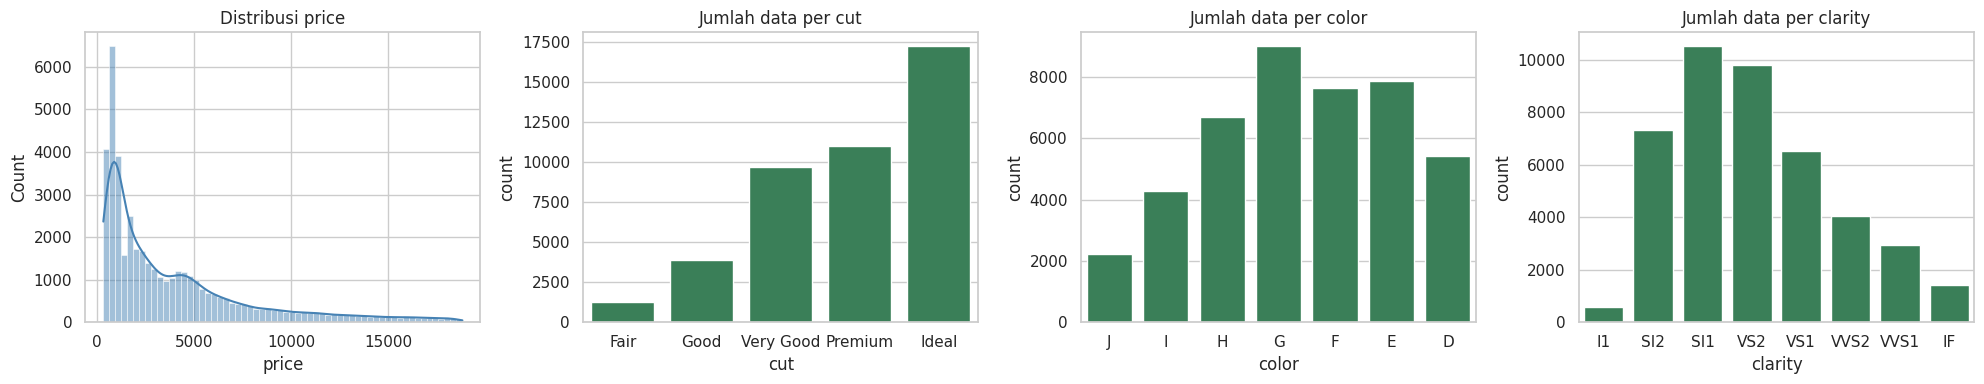

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.histplot(train["price"], bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi price")
for ax, col, order in zip(
    axes[1:],
    ["cut", "color", "clarity"],
    [["Fair", "Good", "Very Good", "Premium", "Ideal"],
     ["J", "I", "H", "G", "F", "E", "D"],
     ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]],
):
    sns.countplot(data=train, x=col, order=order, ax=ax, color="seagreen")
    ax.set_title(f"Jumlah data per {col}")
plt.tight_layout()
plt.show()

**Temuan dari statistik deskriptif:**
- `price` **sangat condong ke kanan** (*skewness* positif besar, mean jauh di atas median): banyak berlian murah, sedikit yang sangat mahal.
- Terdapat nilai **minimum 0 pada `x`, `y`, `z`** (mustahil secara fisik) dan nilai **maksimum yang sangat jauh** dari median pada `y`/`z`. Keduanya indikasi anomali/outlier yang akan ditangani.
- Kategori pada `cut`, `color`, `clarity` **tidak seimbang** (misalnya `Ideal` jauh lebih banyak daripada `Fair`). Ini wajar untuk data nyata dan tidak perlu diubah.
- Skala fitur sangat berbeda (`carat` ±0-5, `table` ±50-70), sehingga **standardisasi** akan dilakukan.

## 5. Mengatasi Missing Value

Pemeriksaan missing value mencegah error pada model dan analisis. Langkahnya mengikuti materi:
1. Hitung missing value per kolom.
2. Pisahkan kolom dengan missing value **< 75%** (`less`, diisi) dan **≥ 75%** (`over`, dihapus).
3. Numerik diisi **median**, kategorikal diisi **modus**.

In [7]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
hilang = missing_values[missing_values > 0]
print("Total nilai hilang:", int(missing_values.sum()))
hilang

Total nilai hilang: 0


Series([], dtype: int64)

In [8]:
# Batas 75% dari jumlah baris
batas = 0.75 * len(train)
less = missing_values[missing_values < batas].index
over = missing_values[missing_values >= batas].index
print("Kolom dengan missing < 75% :", list(less))
print("Kolom dengan missing >= 75%:", list(over))

Kolom dengan missing < 75% : ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']
Kolom dengan missing >= 75%: []


In [9]:
# Mengisi nilai hilang kolom numerik dengan median
numeric_features = train[less].select_dtypes(include=["number"]).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

# Mengisi nilai hilang kolom kategorikal dengan modus
kategorical_features = train[less].select_dtypes(exclude=["number"]).columns
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

# Menghapus kolom dengan terlalu banyak nilai hilang (nama DataFrame diganti agar data asli tetap ada)
df = train.drop(columns=over)

# Simpan statistik dari data latih untuk dipakai pada data uji nanti
median_train = train[numeric_features].median()
mode_train = {c: train[c].mode()[0] for c in kategorical_features}

# Verifikasi
missing_values = df.isnull().sum()
print("Missing value tersisa:", int(missing_values.sum()))
missing_values[missing_values > 0]

Missing value tersisa: 0


Series([], dtype: int64)

**Hasil:** dataset ini **tidak memiliki missing value** (kolom `over` juga kosong), jadi tidak ada data yang diubah atau dihapus pada tahap ini. Kodenya tetap dijalankan sebagai pemeriksaan kualitas data.

## 6. Mengatasi Outlier (Metode IQR)

Outlier dapat mengganggu model. Kita deteksi dengan **IQR**:
- IQR = Q3 − Q1
- Batas bawah = Q1 − 1.5 × IQR, batas atas = Q3 + 1.5 × IQR

Pada materi, outlier **dihapus** dengan asumsi merupakan *human error*. Kita mengikuti pendekatan itu pada **fitur numerik**.

**Kolom target `price` sengaja tidak ikut dipangkas.** Harga berlian memang condong ke kanan: berlian mahal adalah data yang sah, bukan kesalahan input. Memangkas target akan membuang berlian mahal dan membuat evaluasi terlihat lebih mudah dari kenyataan.

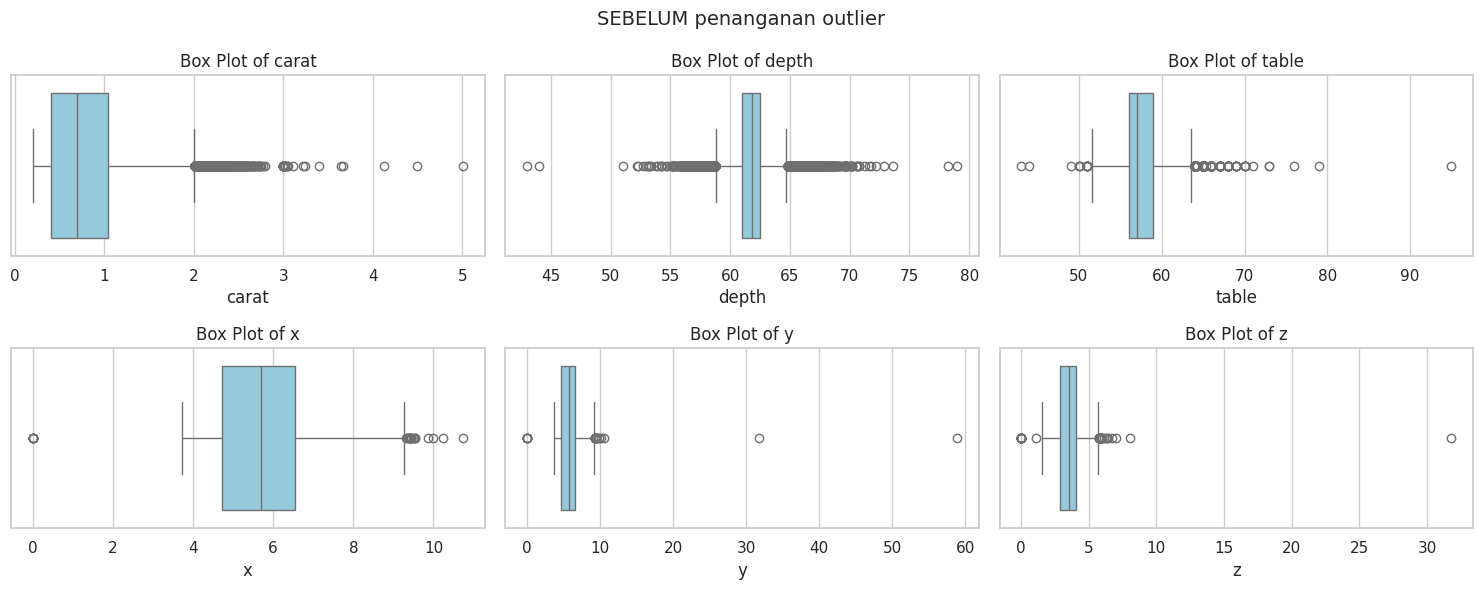

In [10]:
# Fitur numerik (tanpa target price)
fitur_numerik = [c for c in numeric_features if c != "price"]

def tampilkan_boxplot(frame, judul):
    fig, axes = plt.subplots(2, 3, figsize=(15, 6))
    for ax, feature in zip(axes.ravel(), fitur_numerik):
        sns.boxplot(x=frame[feature], ax=ax, color="skyblue")
        ax.set_title(f"Box Plot of {feature}")
    fig.suptitle(judul, fontsize=14)
    plt.tight_layout()
    plt.show()

tampilkan_boxplot(df, "SEBELUM penanganan outlier")

In [11]:
# Menghitung Q1, Q3, IQR, dan batas
Q1 = df[fitur_numerik].quantile(0.25)
Q3 = df[fitur_numerik].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

jumlah_outlier = ((df[fitur_numerik] < batas_bawah) | (df[fitur_numerik] > batas_atas)).sum()
tabel_batas = pd.DataFrame({
    "batas_bawah": batas_bawah, "batas_atas": batas_atas, "jumlah_outlier": jumlah_outlier
})
tabel_batas.round(3)

,batas_bawah,batas_atas,jumlah_outlier
carat,-0.560,2.000,1510
depth,58.750,64.750,2020
table,51.500,63.500,479
x,1.990,9.270,25
y,2.015,9.255,24
z,1.215,5.735,42


Baris sebelum: 43152
Baris sesudah: 39465  (dihapus 3687 baris = 8.5%)


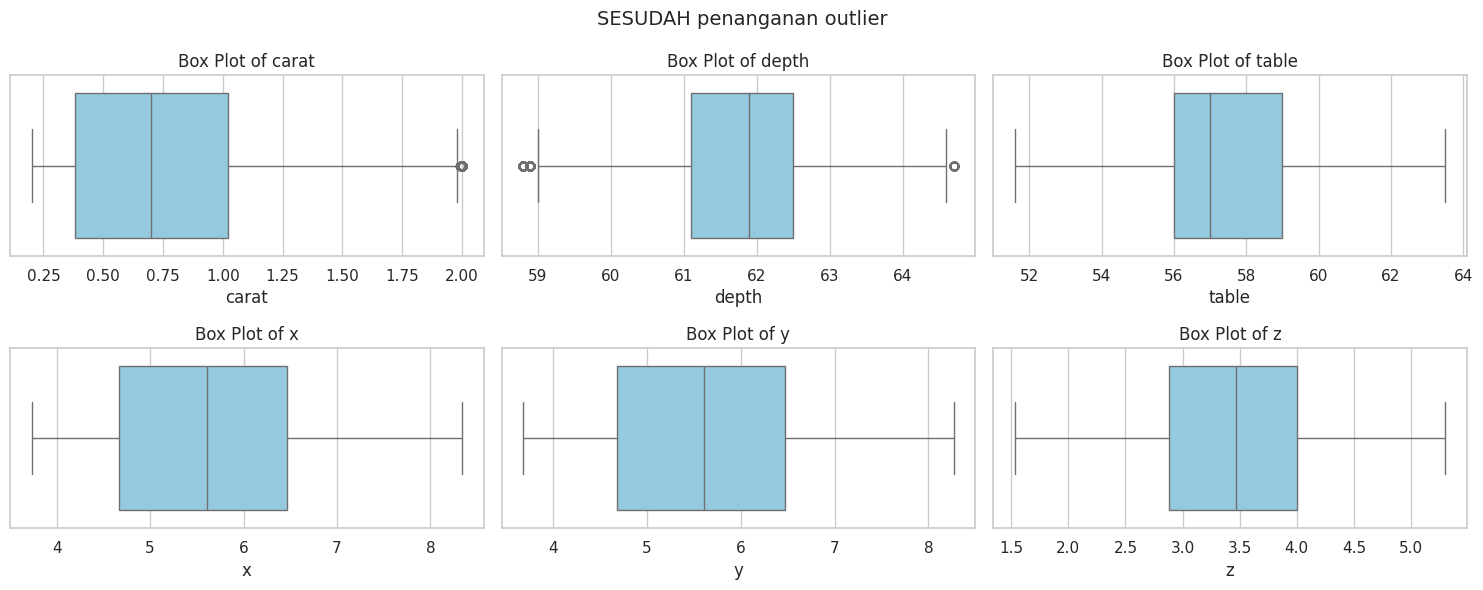

In [12]:
# Menyimpan hanya baris yang tidak mengandung outlier pada fitur numerik
condition = ~((df[fitur_numerik] < batas_bawah) | (df[fitur_numerik] > batas_atas)).any(axis=1)

df_sebelum = df.copy()
df = df.loc[condition].reset_index(drop=True)

print(f"Baris sebelum: {len(df_sebelum)}")
print(f"Baris sesudah: {len(df)}  (dihapus {len(df_sebelum) - len(df)} baris = {(1 - len(df)/len(df_sebelum))*100:.1f}%)")
tampilkan_boxplot(df, "SESUDAH penanganan outlier")

In [13]:
# Perbandingan statistik sebelum vs sesudah
pd.concat(
    {"Sebelum": df_sebelum[fitur_numerik].describe().T[["mean", "std", "min", "max"]],
     "Sesudah": df[fitur_numerik].describe().T[["mean", "std", "min", "max"]]},
    axis=1,
).round(3)

Sebelum                     Sesudah                     
         mean    std   min    max    mean    std    min    max
carat   0.798  0.473   0.2   5.01   0.741  0.401   0.20   2.00
depth  61.743  1.428  43.0  79.00  61.778  1.107  58.80  64.70
table  57.460  2.229  43.0  95.00  57.275  2.017  51.60  63.50
x       5.733  1.120   0.0  10.74   5.618  1.026   3.73   8.34
y       5.736  1.147   0.0  58.90   5.622  1.021   3.68   8.27
z       3.539  0.708   0.0  31.80   3.472  0.635   1.53   5.30

Setelah IQR, rentang data menyusut, standar deviasi mengecil, dan nilai tidak wajar (dimensi 0, `y`/`z` ekstrem) hilang.

⚠️ **Konsekuensi yang perlu disadari:** berlian yang sangat besar (carat tinggi) ikut terbuang karena dianggap outlier oleh IQR. Model akhir lebih andal untuk berlian berukuran *umum* dan kurang andal untuk berlian sangat besar.

## 7. Menangani Duplikasi Data

Berbeda dengan contoh di materi (yang tidak memiliki duplikat), dataset Diamonds **memiliki baris duplikat**,
sehingga langkah ini perlu dijalankan.

In [14]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Jumlah baris duplikat:", int(duplicates.sum()))
df[duplicates].head()

Jumlah baris duplikat: 74


,carat,cut,color,clarity,depth,table,price,x,y,z
2200,0.57,Premium,E,SI2,62.5,54.0,1058,5.35,5.30,3.33
3184,1.00,Ideal,E,SI2,62.9,56.0,3450,6.32,6.30,3.97
4347,0.32,Ideal,D,SI1,62.9,56.0,706,4.40,4.38,2.76
6048,1.04,Premium,I,SI2,62.0,57.0,3774,6.53,6.47,4.03
9266,0.41,Ideal,G,IF,61.7,56.0,1367,4.77,4.80,2.95


In [15]:
# Menghapus baris duplikat
df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran data latih setelah hapus duplikat:", df.shape)

Ukuran data latih setelah hapus duplikat: (39391, 10)


## 8. Mengonversi Tipe Data (Encoding)

Model ML hanya menerima input numerik, jadi `cut`, `color`, dan `clarity` harus di-*encode*.
Materi memperkenalkan tiga pendekatan. Kita bandingkan dulu agar terlihat bedanya.

### 8.1 One-Hot Encoding

In [16]:
category_features = df.select_dtypes(exclude=["number"]).columns.tolist()
print("Fitur kategorikal:", category_features)
assert category_features == ["cut", "color", "clarity"]

df_one_hot = pd.get_dummies(df, columns=category_features)
print(f"Jumlah kolom sebelum: {df.shape[1]} -> sesudah one-hot: {df_one_hot.shape[1]}")

Fitur kategorikal: ['cut', 'color', 'clarity']
Jumlah kolom sebelum: 10 -> sesudah one-hot: 27


### 8.2 Label Encoding
`LabelEncoder` tidak menambah kolom, tetapi ia memberi angka berdasarkan **urutan alfabet**, bukan urutan kualitas. Lihat hasilnya pada `cut`:

In [17]:
le = LabelEncoder().fit(df["cut"])
print("Hasil LabelEncoder pada cut:", dict(zip(le.classes_, le.transform(le.classes_))))

Hasil LabelEncoder pada cut: {'Fair': np.int64(0), 'Good': np.int64(1), 'Ideal': np.int64(2), 'Premium': np.int64(3), 'Very Good': np.int64(4)}


Perhatikan: `Ideal` (kualitas terbaik) mendapat angka 2, sedangkan `Very Good` mendapat 4, **urutannya salah**. Untuk data ordinal seperti ini, `LabelEncoder` menyesatkan model.

### 8.3 Ordinal Encoding (dipilih)
`cut`, `color`, dan `clarity` memiliki **urutan kualitas yang jelas**, sehingga kita pakai `OrdinalEncoder` dengan urutan yang kita tentukan sendiri (angka lebih besar = kualitas lebih baik). Ini juga tidak menambah dimensi seperti one-hot.

In [18]:
cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

ordinal_encoder = OrdinalEncoder(categories=[cut_order, color_order, clarity_order])

df_encoded = df.copy()
df_encoded[category_features] = ordinal_encoder.fit_transform(df[category_features])
print("Sisa kolom non-numerik:", df_encoded.select_dtypes(exclude="number").columns.tolist())
df_encoded.head()

Sisa kolom non-numerik: []


,carat,cut,color,clarity,depth,table,price,x,y,z
0,1.01,2.0,5.0,1.0,60.0,60.0,4540,6.57,6.49,3.92
1,1.10,3.0,2.0,3.0,62.5,58.0,5729,6.59,6.54,4.10
2,1.52,2.0,3.0,4.0,62.1,57.0,12968,7.27,7.32,4.53
3,0.56,3.0,3.0,6.0,59.7,59.0,2167,5.41,5.35,3.21
4,0.30,4.0,4.0,6.0,61.9,55.0,1041,4.32,4.34,2.68


## 9. Normalisasi dan Standardisasi

Skala fitur berbeda-beda, sehingga dilakukan **standardisasi** (rata-rata 0, standar deviasi 1), sesuai pilihan materi untuk model berbasis regresi.

Dua penyesuaian dari contoh materi:
- Hanya **fitur** yang distandardisasi, **target `price` tidak**, supaya MAE dan RMSE tetap bersatuan USD dan mudah dibaca.
- `scaler` di-`fit` pada **data latih saja**, lalu dipakai untuk mentransformasi data uji.

In [19]:
X_train_raw = df_encoded.drop(columns="price")
y_train = df_encoded["price"]
feature_names = X_train_raw.columns.tolist()

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=feature_names, index=X_train_raw.index)

print("Rata-rata setelah standardisasi (harus ~0):")
print(X_train.mean().round(6).to_dict())
print("Std setelah standardisasi (harus ~1):")
print(X_train.std().round(3).to_dict())

Rata-rata setelah standardisasi (harus ~0):
{'carat': -0.0, 'cut': 0.0, 'color': 0.0, 'clarity': 0.0, 'depth': -0.0, 'table': 0.0, 'x': -0.0, 'y': 0.0, 'z': -0.0}
Std setelah standardisasi (harus ~1):
{'carat': 1.0, 'cut': 1.0, 'color': 1.0, 'clarity': 1.0, 'depth': 1.0, 'table': 1.0, 'x': 1.0, 'y': 1.0, 'z': 1.0}


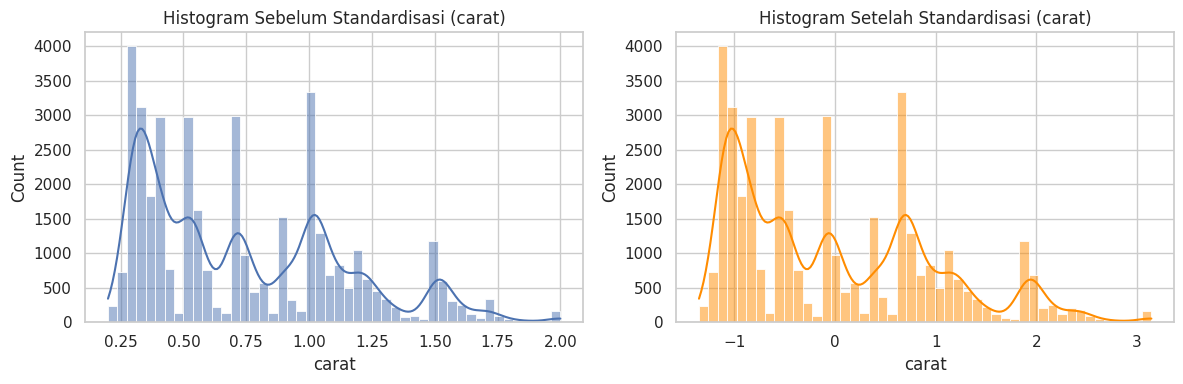

In [20]:
# Histogram sebelum dan sesudah standardisasi (contoh: carat)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(X_train_raw["carat"], kde=True)
plt.title("Histogram Sebelum Standardisasi (carat)")
plt.subplot(1, 2, 2)
sns.histplot(X_train["carat"], kde=True, color="darkorange")
plt.title("Histogram Setelah Standardisasi (carat)")
plt.tight_layout()
plt.show()

Bentuk distribusi tetap sama, hanya skalanya yang berubah (berpusat di 0). Itulah ciri standardisasi.

## 10. Menerapkan Langkah yang Sama pada `test.csv`

Sesuai catatan materi, cleaning juga dilakukan pada data uji. Aturannya: **semua nilai acuan berasal dari data latih**
(median/modus, batas IQR, encoder, scaler), bukan dihitung ulang dari data uji.

Selain itu, baris data uji yang **identik dengan baris di data latih dibuang** untuk mencegah kebocoran
(dataset ini punya duplikat, sehingga satu baris bisa jatuh di kedua sisi pembagian).

In [21]:
te = test.copy()
n_awal = len(te)

# 1. Missing value: pakai median/modus dari data latih
te[numeric_features] = te[numeric_features].fillna(median_train)
for c in kategorical_features:
    te[c] = te[c].fillna(mode_train[c])
te = te.drop(columns=over)

# 2. Outlier: pakai batas IQR dari data latih
mask_ok = ~((te[fitur_numerik] < batas_bawah) | (te[fitur_numerik] > batas_atas)).any(axis=1)
te = te.loc[mask_ok]
n_outlier = n_awal - len(te)

# 3. Duplikat di dalam data uji
n_sebelum_dup = len(te)
te = te.drop_duplicates()
n_dup_internal = n_sebelum_dup - len(te)

# 4. Baris yang identik dengan baris di data latih (cegah kebocoran)
kolom = te.columns.tolist()
acuan_train = train.drop(columns=over)[kolom].drop_duplicates()
cek = te.merge(acuan_train, on=kolom, how="left", indicator=True)
te = cek.loc[cek["_merge"] == "left_only"].drop(columns="_merge").reset_index(drop=True)
n_bocor = n_sebelum_dup - n_dup_internal - len(te)

print(f"Baris awal data uji             : {n_awal}")
print(f"Dibuang (outlier)               : {n_outlier}")
print(f"Dibuang (duplikat internal)     : {n_dup_internal}")
print(f"Dibuang (identik dengan train)  : {n_bocor}")
print(f"Baris data uji akhir            : {len(te)}")

# 5. Encoding dan standardisasi memakai objek yang sudah di-fit pada data latih
te[category_features] = ordinal_encoder.transform(te[category_features])
y_test = te["price"]
X_test = pd.DataFrame(scaler.transform(te[feature_names]), columns=feature_names, index=te.index)

print("\nX_train:", X_train.shape, "| X_test:", X_test.shape)
assert X_test.isna().sum().sum() == 0 and X_train.isna().sum().sum() == 0

Baris awal data uji             : 10788
Dibuang (outlier)               : 949
Dibuang (duplikat internal)     : 5
Dibuang (identik dengan train)  : 34
Baris data uji akhir            : 9800

X_train: (39391, 9) | X_test: (9800, 9)


## 11. Pelatihan Model

Tiga model dibandingkan:
1. **Linear Regression**: baseline sederhana.
2. **Ridge Regression**: regresi linear dengan regularisasi L2 untuk menangani multikolinearitas (`carat`, `x`, `y`, `z` sangat berkorelasi). Nilai `alpha` dicari dengan `GridSearchCV` (5-fold CV) **hanya pada data latih**.
3. **Gradient Boosting Regressor**: ensemble pohon keputusan yang mampu menangkap hubungan non-linear.

In [22]:
# 1. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# 2. Ridge Regression + tuning alpha
ridge_grid = GridSearchCV(
    Ridge(),
    param_grid={"alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
ridge_grid.fit(X_train, y_train)
ridge = ridge_grid.best_estimator_
print("Alpha terbaik Ridge:", ridge_grid.best_params_["alpha"])

# 3. Gradient Boosting Regressor
gbr = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.1, max_depth=4, subsample=0.8, random_state=RANDOM_STATE
)
gbr.fit(X_train, y_train)
print("Ketiga model selesai dilatih.")

Alpha terbaik Ridge: 10


Ketiga model selesai dilatih.


## 12. Evaluasi Model

Metrik pada **data uji**:
- **MAE**: rata-rata selisih absolut prediksi dan harga asli (USD).
- **MSE**: rata-rata kuadrat selisih; menghukum kesalahan besar lebih berat.
- **RMSE**: akar MSE, bersatuan USD.
- **R²**: proporsi variasi harga yang dijelaskan model (semakin dekat 1 semakin baik).

Kolom **R2 (Train)** disertakan untuk mengecek *overfitting*.

In [23]:
models = {"Linear Regression": lr, "Ridge Regression": ridge, "Gradient Boosting": gbr}

def evaluate(model):
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    return {
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 (Test)": r2_score(y_test, pred),
        "R2 (Train)": r2_score(y_train, model.predict(X_train)),
    }

results = pd.DataFrame({name: evaluate(m) for name, m in models.items()}).T.sort_values("RMSE")
results.to_csv("hasil_evaluasi.csv", index_label="Model")
results.round(4)

,MAE,MSE,RMSE,R2 (Test),R2 (Train)
Gradient Boosting,232.3649,1.804544e+05,424.7992,0.9846,0.9883
Linear Regression,715.6273,1.119455e+06,1058.0431,0.9043,0.9067
Ridge Regression,716.2802,1.119938e+06,1058.2714,0.9042,0.9067


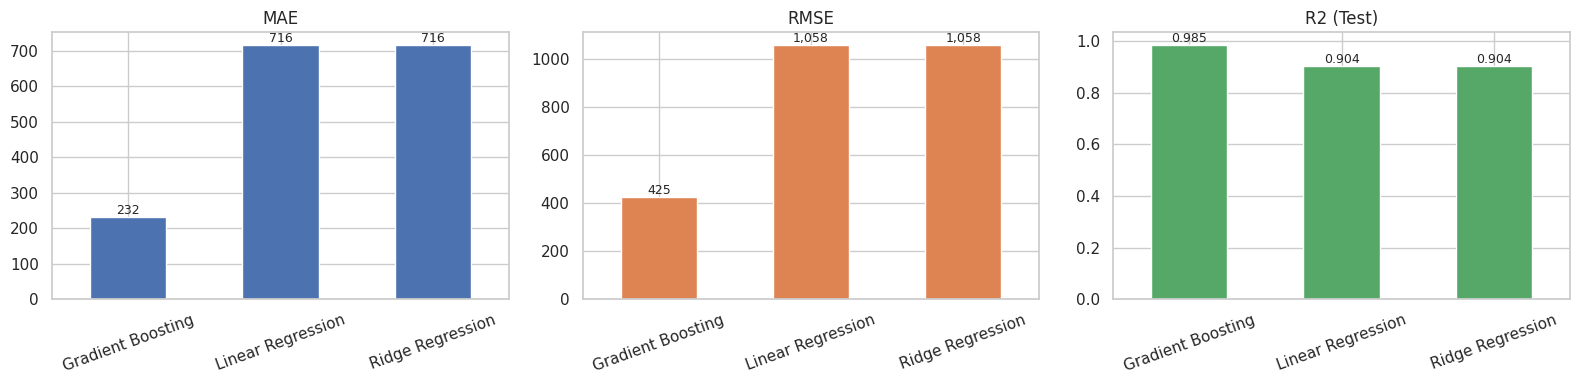

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, color in zip(axes, ["MAE", "RMSE", "R2 (Test)"], ["#4c72b0", "#dd8452", "#55a868"]):
    results[metric].plot(kind="bar", ax=ax, color=color)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for p in ax.patches:
        label = f"{p.get_height():.3f}" if metric == "R2 (Test)" else f"{p.get_height():,.0f}"
        ax.annotate(label, (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### 12.1 Prediksi vs Aktual dan Residual (model terbaik)

Model terbaik (RMSE terendah): Gradient Boosting


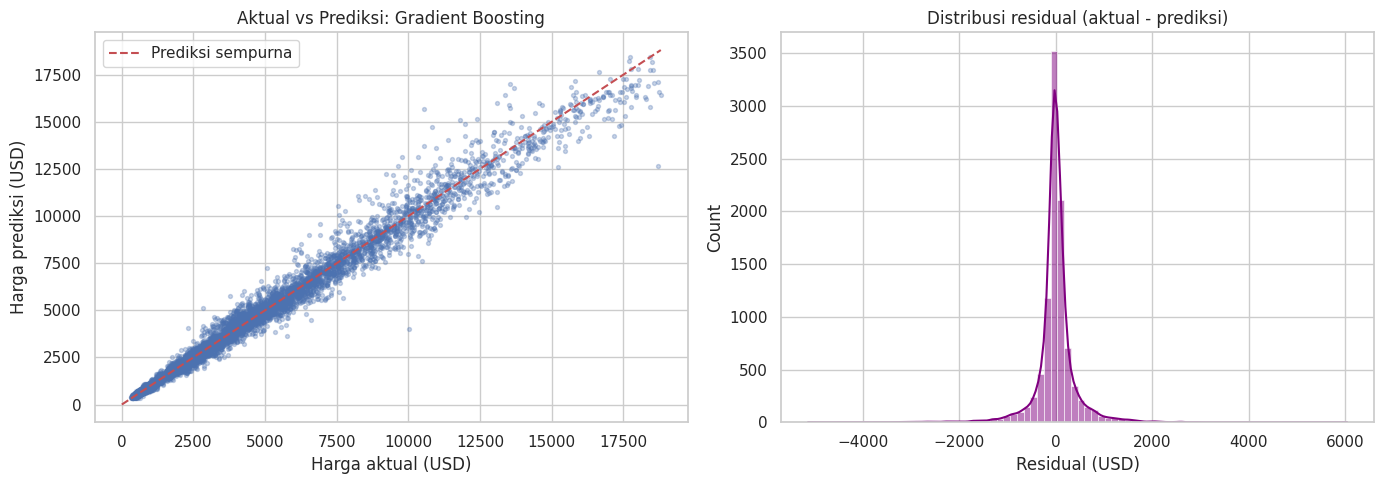

In [25]:
best_name = results["RMSE"].idxmin()
best_model = models[best_name]
pred = best_model.predict(X_test)
print("Model terbaik (RMSE terendah):", best_name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, pred, alpha=0.3, s=8)
lim = [0, max(y_test.max(), pred.max())]
axes[0].plot(lim, lim, "r--", label="Prediksi sempurna")
axes[0].set_xlabel("Harga aktual (USD)")
axes[0].set_ylabel("Harga prediksi (USD)")
axes[0].set_title(f"Aktual vs Prediksi: {best_name}")
axes[0].legend()
sns.histplot(y_test - pred, bins=80, kde=True, ax=axes[1], color="purple")
axes[1].set_title("Distribusi residual (aktual - prediksi)")
axes[1].set_xlabel("Residual (USD)")
plt.tight_layout()
plt.show()

### 12.2 Pentingnya Fitur (Gradient Boosting)

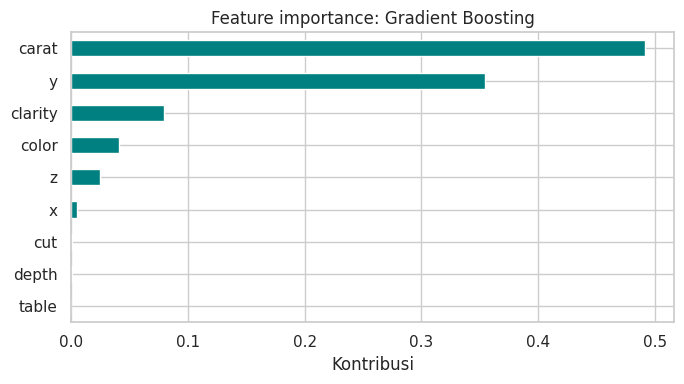

In [26]:
importance = pd.Series(gbr.feature_importances_, index=feature_names).sort_values()
importance.plot(kind="barh", figsize=(7, 4), color="teal")
plt.title("Feature importance: Gradient Boosting")
plt.xlabel("Kontribusi")
plt.tight_layout()
plt.show()

## 13. Menyimpan Model Terbaik

Model dengan **RMSE terendah** disimpan dengan `joblib`. Karena data baru harus melewati *encoding* dan *standardisasi*
yang sama, `ordinal_encoder` dan `scaler` ikut disimpan dalam satu paket bersama model. Setelah itu, file dimuat ulang
untuk memastikan prediksinya identik.

In [27]:
bundle = {
    "model_name": best_name,
    "model": best_model,
    "ordinal_encoder": ordinal_encoder,
    "scaler": scaler,
    "feature_names": feature_names,
    "category_features": category_features,
}
joblib.dump(bundle, "best_model.joblib")
print(f"Model '{best_name}' disimpan ke best_model.joblib")

loaded = joblib.load("best_model.joblib")
assert np.allclose(loaded["model"].predict(X_test), best_model.predict(X_test))
print("Verifikasi berhasil: prediksi model hasil load sama dengan model asli.")

Model 'Gradient Boosting' disimpan ke best_model.joblib
Verifikasi berhasil: prediksi model hasil load sama dengan model asli.


### Contoh penggunaan model tersimpan
Data baru berupa nilai **mentah** (teks untuk kategori); encoding dan standardisasi dilakukan oleh fungsi di bawah.

In [28]:
def prediksi_harga(data_baru, paket):
    d = pd.DataFrame(data_baru)
    d[paket["category_features"]] = paket["ordinal_encoder"].transform(d[paket["category_features"]])
    d = d[paket["feature_names"]]
    return paket["model"].predict(paket["scaler"].transform(d))

contoh = [{
    "carat": 1.0, "cut": "Ideal", "color": "G", "clarity": "VS2",
    "depth": 61.5, "table": 56.0, "x": 6.4, "y": 6.4, "z": 3.95,
}]
print(f"Prediksi harga contoh berlian: ${prediksi_harga(contoh, loaded)[0]:,.0f}")

Prediksi harga contoh berlian: $6,274


## 14. Kesimpulan

- Alur cleaning mengikuti materi: info dataset → statistik deskriptif → missing value → outlier (IQR) → duplikat → encoding → standardisasi, lalu diterapkan juga pada data uji dengan acuan dari data latih.
- Dataset ini **tidak punya missing value**, tetapi memiliki **dimensi bernilai 0, outlier ekstrem, dan baris duplikat** yang berhasil ditangani.
- `cut`, `color`, `clarity` bersifat **ordinal**, sehingga dipakai `OrdinalEncoder` dengan urutan eksplisit. `LabelEncoder` sengaja tidak dipakai karena mengurutkan secara alfabet.
- Perbandingan tiga model ada pada tabel di bagian 12. Model berbasis pohon umumnya unggul karena hubungan fitur dan harga bersifat non-linear.
- Keterbatasan: pemangkasan outlier membuang berlian sangat besar, sehingga model kurang andal untuk rentang tersebut.

**Pengembangan lanjutan:** transformasi log pada target, tuning hyperparameter yang lebih luas (`RandomizedSearchCV`), serta mencoba Random Forest atau XGBoost.